Brianna Aceves | DSC360 | 9.2 Exercise

In [1]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

#Tools for splitting data and preparing text
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

#Neural network model
from sklearn.neural_network import MLPClassifier

#Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


I started by importing the libraries needed for the sentiment analysis exercise. I'm using pandas to work with the dataset, Scikit-learn to prepare the text and build the neural network, and Matplotlib to visualize some of the results. I decided to use Scikit-learn for this assignment as well.

In [2]:
#Load the hotel reviews dataset
df = pd.read_csv("hotel-reviews.csv")

#Review the dataset size and first five rows
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (38932, 5)


,User_ID,Description,Browser_Used,Device_Used,Is_Response
0,id10326,The room was kind of clean but had a VERY stro...,Edge,Mobile,not happy
1,id10327,I stayed at the Crown Plaza April -- - April -...,Internet Explorer,Mobile,not happy
2,id10328,I booked this hotel through Hotwire at the low...,Mozilla,Tablet,not happy
3,id10329,Stayed here with husband and sons on the way t...,InternetExplorer,Desktop,happy
4,id10330,My girlfriends and I stayed here to celebrate ...,Edge,Tablet,not happy


After loading the hotel reviews dataset, I found that it contains 38,932 records and 5 columns. The columns include User_ID, Description, Browser_Used, Device_Used, and Is_Response. For this exercise, I'll mainly focus on Description, which contains the written hotel reviews, and Is_Response, which tells us whether the guest was happy or not happy. I also noticed that some of the first few reviews were labeled as "not happy." The overall goal is to train a neural network to recognize patterns in the written reviews and predict the sentiment.

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38932 entries, 0 to 38931
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   User_ID       38932 non-null  object
 1   Description   38932 non-null  object
 2   Browser_Used  38932 non-null  object
 3   Device_Used   38932 non-null  object
 4   Is_Response   38932 non-null  object
dtypes: object(5)
memory usage: 1.5+ MB

Missing Values:
Description    0
Is_Response    0
dtype: int64

Sentiment Distribution:
Is_Response
happy        26521
not happy    12411
Name: count, dtype: int64


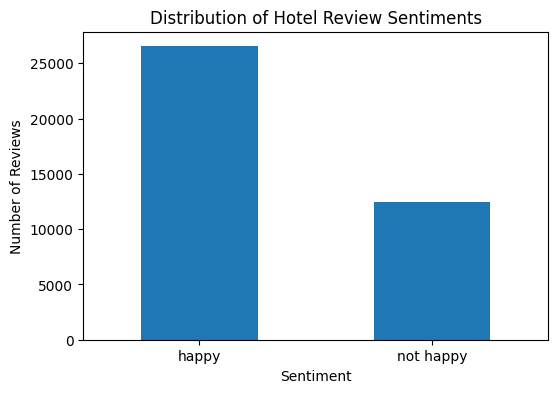

In [3]:
#Check the columns and missing values
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df[["Description", "Is_Response"]].isnull().sum())

print("\nSentiment Distribution:")
print(df["Is_Response"].value_counts())

#Display the sentiment distribution
df["Is_Response"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Distribution of Hotel Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

After checking the dataset, I found that all 38,932 records have complete information, so there aren't any missing values to worry about. I also looked at the distribution of the sentiment labels and noticed that there are quite a few more happy reviews than not happy reviews. There are 26,521 happy reviews compared to 12,411 not happy reviews. This tells me the dataset is a little imbalanced, which could affect how the model learns to classify the reviews. I'll keep this in mind when evaluating the results, since I want the model to recognize both happy and not happy reviews rather than mostly predicting the larger category.

In [4]:
#Keep only the columns needed for sentiment analysis
df = df[["Description", "Is_Response"]].copy()

#Remove any missing values
df = df.dropna(subset=["Description", "Is_Response"])

#Standardize the sentiment labels
df["Is_Response"] = (
    df["Is_Response"].astype(str).str.strip().str.lower()
)

#Encode sentiment labels into numerical values
sentiment_mapping = {
    "happy": 0,
    "not happy": 1
}

df["sentiment_label"] = df["Is_Response"].map(sentiment_mapping)

#Check the encoded sentiment labels
print("Sentiment Label Mapping:")
print(sentiment_mapping)

print("\nEncoded Sentiment Distribution:")
print(df["sentiment_label"].value_counts().sort_index())

#Display the first five rows
display(df.head())

Sentiment Label Mapping:
{'happy': 0, 'not happy': 1}

Encoded Sentiment Distribution:
sentiment_label
0    26521
1    12411
Name: count, dtype: int64


,Description,Is_Response,sentiment_label
0,The room was kind of clean but had a VERY stro...,not happy,1
1,I stayed at the Crown Plaza April -- - April -...,not happy,1
2,I booked this hotel through Hotwire at the low...,not happy,1
3,Stayed here with husband and sons on the way t...,happy,0
4,My girlfriends and I stayed here to celebrate ...,not happy,1


I converted the sentiment labels into numerical values so the neural network can use them for classification. I assigned 0 to happy reviews and 1 to not happy reviews, as instructed. After encoding, I checked the results and confirmed that there were still 26,521 happy reviews and 12,411 not happy reviews, so no records were lost during this process. I also kept the original sentiment column so I could compare the labels and make sure they were converted correctly.

In [5]:
#Create a function to clean the review text
def clean_text(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove punctuation except apostrophes
    text = re.sub(r"[^a-z\s']", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

#Apply text cleaning to the hotel reviews
df["cleaned_review"] = df["Description"].apply(clean_text)

#Remove any reviews that become empty after cleaning
df = df[df["cleaned_review"].str.len() > 0].copy()

#Compare the original and cleaned reviews
display(
    df[["Description", "cleaned_review", "sentiment_label"]].head()
)

print("Remaining Reviews:", len(df))

,Description,cleaned_review,sentiment_label
0,The room was kind of clean but had a VERY stro...,the room was kind of clean but had a very stro...,1
1,I stayed at the Crown Plaza April -- - April -...,i stayed at the crown plaza april april the st...,1
2,I booked this hotel through Hotwire at the low...,i booked this hotel through hotwire at the low...,1
3,Stayed here with husband and sons on the way t...,stayed here with husband and sons on the way t...,0
4,My girlfriends and I stayed here to celebrate ...,my girlfriends and i stayed here to celebrate ...,1


Remaining Reviews: 38932


I cleaned the hotel reviews to make the text more consistent before training the neural network. I converted the reviews to lowercase and removed HTML tags, URLs, unnecessary punctuation, and extra spaces. After comparing the original reviews with the cleaned versions, I could see that the text was more standardized while still keeping the words needed for sentiment analysis. I also checked the number of remaining reviews and confirmed that all 38,932 records were still there, so no reviews were lost during cleaning.

In [6]:
#Separate the cleaned reviews and labels
X = df["cleaned_review"]
y = df["sentiment_label"]

#Split the data into 70% training and 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

#Divide the remaining data into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

#Display the number of samples in each group
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nTotal Samples:",
      len(X_train) + len(X_val) + len(X_test))

#Check sentiment distribution across each dataset
print("\nSentiment Distribution by Split:")

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(
        name,
        labels.value_counts(normalize=True).sort_index().round(3).to_dict()
    )

Training Samples: 27252
Validation Samples: 5840
Testing Samples: 5840

Total Samples: 38932

Sentiment Distribution by Split:
Training {0: 0.681, 1: 0.319}
Validation {0: 0.681, 1: 0.319}
Testing {0: 0.681, 1: 0.319}


I divided the 38,932 hotel reviews into three groups: 70% for training, 15% for validation, and 15% for testing. This gave me 27,252 reviews for training and 5,840 reviews each for validation and testing. I also used stratification to keep the sentiment distribution consistent across all three groups. After checking the results, each group contained approximately 68.1% happy reviews and 31.9% not happy reviews. This is helpful because the dataset has more happy reviews, and I want both categories to be represented fairly when training and evaluating the model.

In [7]:
#Create a TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=1500,
    min_df=2,
    ngram_range=(1, 2)
)

#Fit the vectorizer using only the training data
X_train_tfidf = tfidf.fit_transform(X_train)

#Transform the validation and testing datasets
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

#Display the shapes of the transformed datasets
print("Training Shape:", X_train_tfidf.shape)
print("Validation Shape:", X_val_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

#Display the total number of TF-IDF features
print("\nNumber of TF-IDF Features:",
      len(tfidf.get_feature_names_out()))

#Display the first 20 features
print("\nFirst 20 TF-IDF Features:")
print(tfidf.get_feature_names_out()[:20])

Training Shape: (27252, 1500)
Validation Shape: (5840, 1500)
Testing Shape: (5840, 1500)

Number of TF-IDF Features: 1500

First 20 TF-IDF Features:
['able' 'able to' 'about' 'about it' 'about the' 'about this' 'above'
 'absolutely' 'access' 'access to' 'accommodating' 'across' 'across the'
 'actually' 'adequate' 'after' 'afternoon' 'again' 'air' 'airport']


I used TF-IDF to convert the cleaned hotel reviews into numerical features that the neural network can understand. I limited the features to 1,500 to help keep the model manageable when training. After running the code, I confirmed that all three datasets had 1,500 features, while keeping their original number of reviews. I also looked at the first 20 features and noticed that they included both individual words and two-word combinations, such as "able" and "able to." I fitted the vectorizer using only the training data to avoid introducing information from the validation or testing datasets.

In [8]:
#Create a neural network for sentiment classification
model = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    max_iter=15,
    random_state=42,
    early_stopping=False,
    verbose=True
)

#Train the neural network using the training dataset
model.fit(X_train_tfidf, y_train)

#Display training results
print("\nNeural Network Training Completed!")
print("Training Iterations:", model.n_iter_)
print("Final Training Loss:", round(model.loss_, 4))

Iteration 1, loss = 0.50909578
Iteration 2, loss = 0.33428998
Iteration 3, loss = 0.28961603
Iteration 4, loss = 0.27225262
Iteration 5, loss = 0.26409216
Iteration 6, loss = 0.25882846
Iteration 7, loss = 0.25547576
Iteration 8, loss = 0.25295846
Iteration 9, loss = 0.25132519
Iteration 10, loss = 0.25052195
Iteration 11, loss = 0.24851278
Iteration 12, loss = 0.24781643
Iteration 13, loss = 0.24698308
Iteration 14, loss = 0.24613942
Iteration 15, loss = 0.24523707

Neural Network Training Completed!
Training Iterations: 15
Final Training Loss: 0.2452


C:\Users\brian\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


I trained a neural network using Scikit-learn's MLPClassifier with one hidden layer containing 32 neurons. I limited the training to 15 iterations to keep the processing time manageable. After running the model, I noticed that the training loss decreased from about 0.5091 to 0.2452, which suggests the model was learning patterns from the hotel reviews. I did receive a convergence warning because the model reached the maximum number of iterations before fully converging. However, since the loss was consistently decreasing, I decided to continue evaluating the model to see how well it performs on the validation and testing datasets.

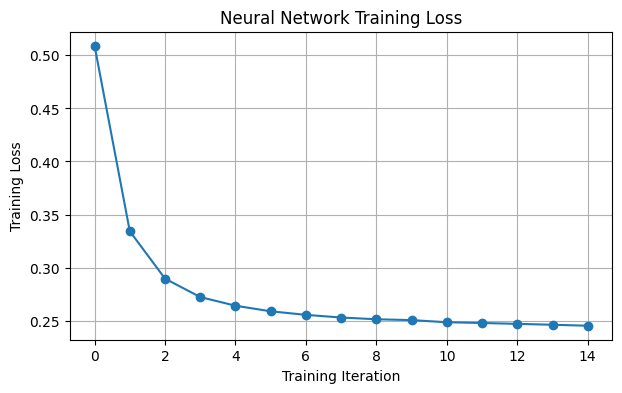

In [9]:
#Plot the neural network training loss
plt.figure(figsize=(7, 4))

plt.plot(
    model.loss_curve_,
    marker="o",
    linestyle="-"
)

#Add graph labels
plt.title("Neural Network Training Loss")
plt.xlabel("Training Iteration")
plt.ylabel("Training Loss")

#Display grid and graph
plt.grid(True)
plt.show()

After graphing the training loss, I could see that the neural network was learning throughout the 15 iterations. The biggest decrease happened during the first few iterations, where the loss dropped pretty quickly. After that, the line started to level off, but the loss continued to decrease gradually until it reached about 0.2452. This suggests that the model was improving as it trained, although the smaller changes toward the end show that the improvements were slowing down. I'll need to check the validation results next to see how well the model performs on reviews it hasn't seen before.

In [10]:
#Predict sentiment using the validation dataset
y_val_pred = model.predict(X_val_tfidf)

#Calculate validation accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Validation Accuracy:", round(val_accuracy, 4))

#Display the classification report
print("\nValidation Classification Report:")

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=["Happy", "Not Happy"],
        zero_division=0
    )
)

Validation Accuracy: 0.8827

Validation Classification Report:
              precision    recall  f1-score   support

       Happy       0.90      0.93      0.91      3979
   Not Happy       0.83      0.79      0.81      1861

    accuracy                           0.88      5840
   macro avg       0.87      0.86      0.86      5840
weighted avg       0.88      0.88      0.88      5840



After testing the neural network on the validation dataset, I got an accuracy of 88.27%, which was better than I expected considering I only trained the model for 15 iterations. The model performed better at identifying happy reviews, with a recall of 0.93 and an F1-score of 0.91. For not happy reviews, the recall was a little lower at 0.79, with an F1-score of 0.81. I think this difference could be related to the dataset having more happy reviews than not happy reviews. Overall, the results seem promising, but I can see that the model has more difficulty recognizing negative reviews. I'll keep the current model and move on to the final testing dataset to see whether the results stay consistent.

In [11]:
#Predict sentiment using the testing dataset
y_test_pred = model.predict(X_test_tfidf)

#Calculate the final testing accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Final Test Accuracy:", round(test_accuracy, 4))

#Display the testing classification report
print("\nTest Classification Report:")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Happy", "Not Happy"],
        zero_division=0
    )
)

#Compare validation and testing accuracy
print("\nAccuracy Comparison:")
print("Validation Accuracy:", round(val_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))

Final Test Accuracy: 0.8683

Test Classification Report:
              precision    recall  f1-score   support

       Happy       0.90      0.91      0.90      3978
   Not Happy       0.81      0.77      0.79      1862

    accuracy                           0.87      5840
   macro avg       0.85      0.84      0.85      5840
weighted avg       0.87      0.87      0.87      5840


Accuracy Comparison:
Validation Accuracy: 0.8827
Testing Accuracy: 0.8683


After testing the neural network on the final dataset, I got an accuracy of 86.83%, which was slightly lower than the validation accuracy of 88.27%. The difference was only about 1.44 percentage points, so the model seems to perform pretty consistently on new reviews. I also noticed that it continued to do better at identifying happy reviews, with a recall of 0.91 compared to 0.77 for not happy reviews. This tells me the model is learning to recognize sentiment, but it still struggles a little more with negative reviews. Overall, I think the results are pretty good considering I limited the training to 15 iterations.

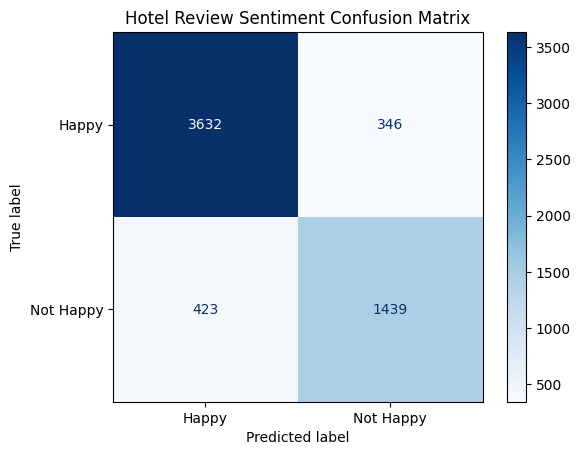

In [12]:
#Create the confusion matrix using testing predictions
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

#Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Happy", "Not Happy"]
)

disp.plot(cmap="Blues")

#Title it
plt.title("Hotel Review Sentiment Confusion Matrix")

plt.show()

After creating the confusion matrix, I was able to see exactly where the neural network was making mistakes. The model correctly classified 3,632 happy reviews and 1,439 not happy reviews. However, it also incorrectly labeled 346 happy reviews as not happy and 423 not happy reviews as happy. This was interesting because it shows that the model has a slightly harder time recognizing negative reviews, which matches what I noticed in the classification report. Overall, the model correctly predicted 5,071 out of 5,840 reviews, so I think it performed pretty well, even though there's still room for improvement.

In [13]:
#Test the model
# Select five actual reviews from the testing dataset
sample_reviews = X_test.sample(
    n=5,
    random_state=42
)

#Convert the reviews using the trained TF-IDF vectorizer
sample_features = tfidf.transform(sample_reviews)

#Predict sentiment
sample_predictions = model.predict(sample_features)

#Get the actual sentiment labels
actual_labels = y_test.loc[sample_reviews.index]

#Create a comparison table
results = pd.DataFrame({
    "Review": sample_reviews.values,
    "Actual Sentiment": actual_labels.map({
        0: "Happy",
        1: "Not Happy"
    }).values,
    "Predicted Sentiment": [
        "Happy" if prediction == 0 else "Not Happy"
        for prediction in sample_predictions
    ]
})

# Display the results
display(results)

,Review,Actual Sentiment,Predicted Sentiment
0,i stayed at the doubletree hotel for three wee...,Happy,Happy
1,nice high end marriott on the bay make sure yo...,Happy,Happy
2,we got a very good deal on the holiday inn via...,Not Happy,Not Happy
3,it's not the nicest property i've been at but ...,Happy,Happy
4,i knew something was strange when i walked rig...,Happy,Not Happy


For this step, I wanted to see how the neural network would perform on individual hotel reviews, so I randomly selected five reviews from the testing dataset. I compared the model's predictions with the actual sentiment labels and found that it correctly classified four out of the five reviews. The one incorrect prediction was a review that was actually labeled happy, but the model predicted it as not happy. I thought this was interesting because it shows that even though the model had an overall testing accuracy of 86.83%, it can still make mistakes when interpreting individual reviews. This helped me see how the model performs beyond just looking at accuracy scores.

In [15]:
#Find reviews where the prediction was incorrect
incorrect_reviews = results[
    results["Actual Sentiment"] != results["Predicted Sentiment"]
]

#Display the full review and its sentiment labels
for index, row in incorrect_reviews.iterrows():
    print("Original Review:")
    print(row["Review"])

    print("\nActual Sentiment:", row["Actual Sentiment"])
    print("Predicted Sentiment:", row["Predicted Sentiment"])

Original Review:
i knew something was strange when i walked right by the hudson there is no sign outside the door two doormen were muttering hudson hotel in the furtive sotto voce i usually associate with sidewalk dealers asking want some herb once i had located the hotel i ascended a long escalator to the lobby the entrance lobby and some other common areas are lit in a creepy yellow green fluorescent perhaps i'm too old to understand chic but to me it resembled minas morgul in the lord of the rings movie the lobby itself is so dim i almost walked into other guests more than once these are not the smallest rooms in nyc i have stayed in the paramount and they are even smaller the bed occupies almost the entire room the shower is at the foot of the bed separated by only a curtain and the toilet is on the far side of the shower i was actually rather impressed with the room's utilization of space putting the stereo in the closet and a tv hinged to the wall i was reminded of rooms in some 

I wanted to look at the full review to see where the neural network misinterpreted. After looking at the review that was incorrectly classified, I could understand why the neural network might have struggled with it. Even though the review was labeled happy, the guest mentioned several negative things, including the small room, strange atmosphere, and creepy lighting. However, they also made some positive comments about the price, use of space, and staff. I thought this was interesting because the review contained a mixture of positive and negative opinions, which may have confused the model. This showed me that sentiment analysis isn't always straightforward, especially when someone has both good and bad things to say about their experience.

For this exercise, I created a sentiment analysis model using the Hotel Reviews dataset and Scikit-learn's MLPClassifier neural network. I started with 38,932 hotel reviews and cleaned the text before converting it into numerical features using TF-IDF. I also encoded the sentiment labels, with 0 representing happy and 1 representing not happy. I divided the dataset into training, validation, and testing groups to evaluate how well the model performed. After training for 15 iterations, the neural network achieved a validation accuracy of 88.27% and a testing accuracy of 86.83%. The results were fairly consistent, although I noticed that the model performed better at identifying happy reviews than not happy reviews. One of the more interesting parts was looking at an incorrectly classified review. The guest included both positive and negative comments, which may have made the sentiment harder for the model to recognize. Overall, this exercise helped me better understand how neural networks can analyze written text and why it's important to look beyond accuracy when evaluating a model.